## Customizable parameters
"interaction": select which dataset to use for the execution (mirna_mirna/circrna_mirna) 

"prefix": select the path prefix based on the running environment (local/colab)

In [ ]:
#interaction = "mirna_mirna"         
interaction = "circrna_mirna"         
prefix = "./"                  
max_sequence_length = 1022 

## Libraries import

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import pickle
import random
from tqdm import tqdm
from multiprocessing import Pool
import os
import numpy as np
import torch
import networkx as nx
import scipy.sparse as sp

# Part 1 - RNA-FM data preparation

## Dataset analisys, split and preparation for training/test

Initial dataset size: 381
Dataset size after removing missing values: 373
Number of unique sequences: 379


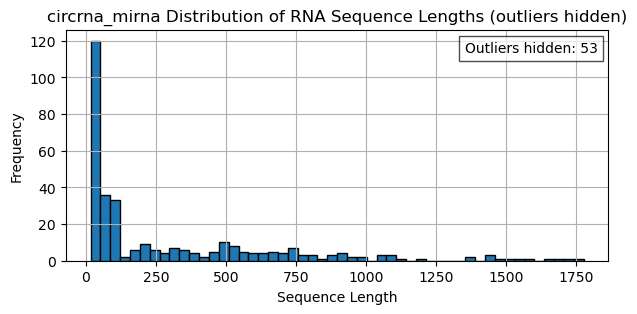

Count sequence couples: 373
Count after filtering sequences exceeding 1022: 159
Training set size:  127
Testing set size:  32


In [16]:
## Csv data read with pandas
path = prefix + interaction + '.csv'
df = pd.read_csv(path)

## Step 1: data analysis and cleaning
# Remove rows with missing values
print("Initial dataset size:", len(df))
df = df.dropna(subset=['RNA_sequence_x', 'RNA_sequence_y', 'Category_x', 'Category_y', 'Category_Couple'])
print("Dataset size after removing missing values:", len(df))

# Count unique sequences
all_sequences = pd.concat([df['RNA_sequence_x'], df['RNA_sequence_y']]).unique()
num_unique_sequences = len(all_sequences)
print(f"Number of unique sequences: {num_unique_sequences}")

# Calculate sequence lengths and plot histogram
sequence_lengths = [len(seq) for seq in all_sequences]

# histogram showing the length of the sequences
lengths = np.array(sequence_lengths)
q1 = np.percentile(lengths, 25)
q3 = np.percentile(lengths, 75)
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

# keep only non-outlier lengths for plotting
filtered_lengths = lengths[(lengths >= lower_bound) & (lengths <= upper_bound)]
outlier_count = len(lengths) - len(filtered_lengths)

plt.figure(figsize=(7, 3))
plt.hist(filtered_lengths, bins=50, edgecolor='black')
plt.title(interaction + ' Distribution of RNA Sequence Lengths (outliers hidden)')
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.grid(True)

# annotate info about removed outliers and bounds
plt.text(0.98, 0.95, f'Outliers hidden: {outlier_count}', transform=plt.gca().transAxes,
         horizontalalignment='right', verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
plt.show()

# Double-check the count before filtering
print('Count sequence couples:', len(df))

# Filter sequences where both x and y are individually ≤ 1022 #   1022 o 4096
filtered_df = df[
    df.apply(
        lambda row: len(row['RNA_sequence_x']) <= max_sequence_length and len(row['RNA_sequence_y']) <= max_sequence_length, axis=1)
]

# Print the count after filtering
print(f'Count after filtering sequences exceeding {max_sequence_length}:', len(filtered_df))

# Perform stratified train-test split
train_df, test_df = train_test_split(
    filtered_df,
    test_size=0.2,
    random_state=42
)
print("Training set size: ", len(train_df))
print("Testing set size: ", len(test_df))

circRNA - Mean length: 1780.6, Median: 1099.0
circRNA - Min: 61, Max: 28771

miRNA - Mean length: 63.8, Median: 22.0
miRNA - Min: 17, Max: 2525


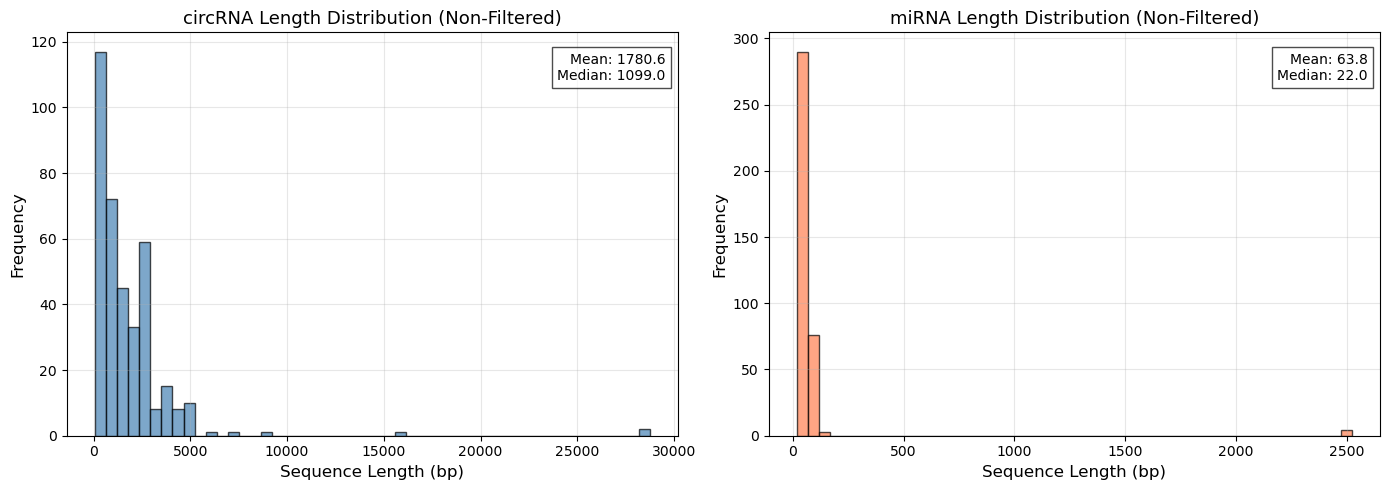

In [ ]:
# Analyze sequence length distribution for non-filtered dataset
# Calculate sequence lengths for x and y positions based on their categories
# Separate sequences by their actual category (circRNA or miRNA)
circrna_lengths_nf = []
mirna_lengths_nf = []

for idx, row in df.iterrows():
    seq_x = row['RNA_sequence_x']
    seq_y = row['RNA_sequence_y']
    cat_x = row['Category_x']
    cat_y = row['Category_y']
    
    # Add sequence_x to the appropriate category
    if cat_x == 'circRNA':
        circrna_lengths_nf.append(len(seq_x))
    elif cat_x == 'miRNA':
        mirna_lengths_nf.append(len(seq_x))
    
    # Add sequence_y to the appropriate category
    if cat_y == 'circRNA':
        circrna_lengths_nf.append(len(seq_y))
    elif cat_y == 'miRNA':
        mirna_lengths_nf.append(len(seq_y))

# Convert to numpy arrays for statistics
circrna_lengths_nf = np.array(circrna_lengths_nf)
mirna_lengths_nf = np.array(mirna_lengths_nf)

# Set category names for plotting
seq_x_category_nf = 'circRNA'
seq_y_category_nf = 'miRNA'
seq_x_lengths_nf = circrna_lengths_nf
seq_y_lengths_nf = mirna_lengths_nf

print(f"{seq_x_category_nf} - Mean length: {np.mean(seq_x_lengths_nf):.1f}, Median: {np.median(seq_x_lengths_nf):.1f}")
print(f"{seq_x_category_nf} - Min: {np.min(seq_x_lengths_nf)}, Max: {np.max(seq_x_lengths_nf)}")
print(f"\n{seq_y_category_nf} - Mean length: {np.mean(seq_y_lengths_nf):.1f}, Median: {np.median(seq_y_lengths_nf):.1f}")
print(f"{seq_y_category_nf} - Min: {np.min(seq_y_lengths_nf)}, Max: {np.max(seq_y_lengths_nf)}")

# Create side-by-side histograms for sequence lengths (non-filtered)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot for circRNA lengths (non-filtered)
axes[0].hist(seq_x_lengths_nf, bins=50, edgecolor='black', color='steelblue', alpha=0.7)
axes[0].set_xlabel('Sequence Length (bp)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title(f'{seq_x_category_nf} Length Distribution (Non-Filtered)', fontsize=13)
axes[0].grid(True, alpha=0.3)
axes[0].text(0.98, 0.95, f'Mean: {np.mean(seq_x_lengths_nf):.1f}\nMedian: {np.median(seq_x_lengths_nf):.1f}', 
             transform=axes[0].transAxes, horizontalalignment='right', 
             verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

# Plot for miRNA lengths (non-filtered)
axes[1].hist(seq_y_lengths_nf, bins=50, edgecolor='black', color='coral', alpha=0.7)
axes[1].set_xlabel('Sequence Length (bp)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title(f'{seq_y_category_nf} Length Distribution (Non-Filtered)', fontsize=13)
axes[1].grid(True, alpha=0.3)
axes[1].text(0.98, 0.95, f'Mean: {np.mean(seq_y_lengths_nf):.1f}\nMedian: {np.median(seq_y_lengths_nf):.1f}', 
             transform=axes[1].transAxes, horizontalalignment='right', 
             verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()

circRNA - Mean length: 455.8, Median: 462.0
circRNA - Min: 61, Max: 1002

miRNA - Mean length: 47.6, Median: 23.0
miRNA - Min: 17, Max: 142


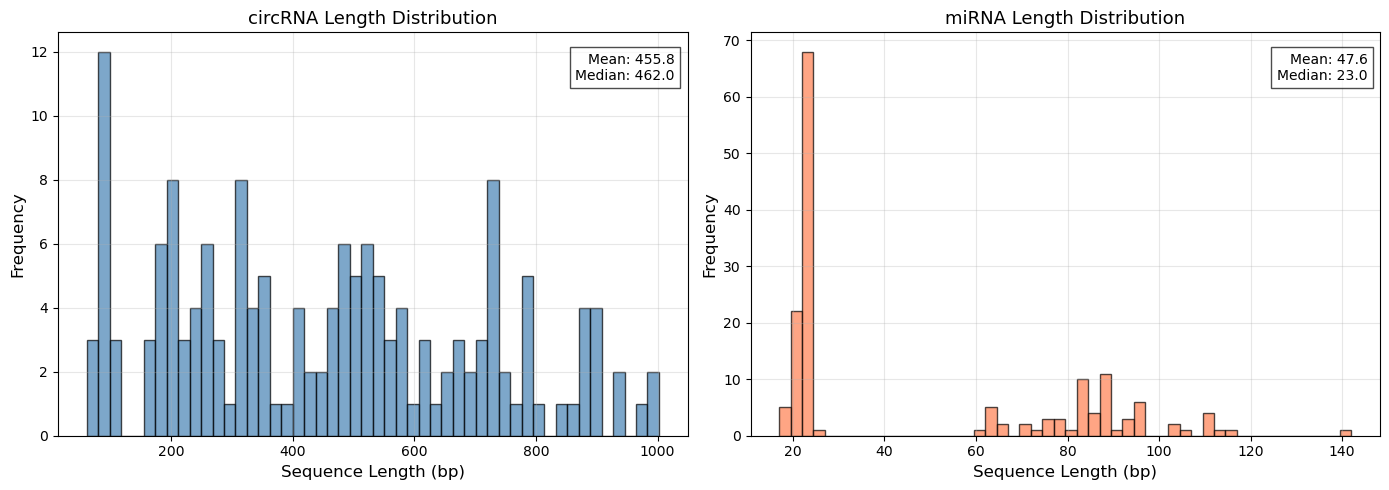

In [18]:
# Analyze sequence length distribution for x and y separately

# Calculate sequence lengths for x and y positions based on their categories
# Separate sequences by their actual category (circRNA or miRNA)
circrna_lengths = []
mirna_lengths = []

for idx, row in filtered_df.iterrows():
    seq_x = row['RNA_sequence_x']
    seq_y = row['RNA_sequence_y']
    cat_x = row['Category_x']
    cat_y = row['Category_y']
    
    # Add sequence_x to the appropriate category
    if cat_x == 'circRNA':
        circrna_lengths.append(len(seq_x))
    elif cat_x == 'miRNA':
        mirna_lengths.append(len(seq_x))
    
    # Add sequence_y to the appropriate category
    if cat_y == 'circRNA':
        circrna_lengths.append(len(seq_y))
    elif cat_y == 'miRNA':
        mirna_lengths.append(len(seq_y))

# Convert to numpy arrays for statistics
circrna_lengths = np.array(circrna_lengths)
mirna_lengths = np.array(mirna_lengths)

# Set category names for plotting
seq_x_category = 'circRNA'
seq_y_category = 'miRNA'
seq_x_lengths = circrna_lengths
seq_y_lengths = mirna_lengths

print(f"{seq_x_category} - Mean length: {np.mean(seq_x_lengths):.1f}, Median: {np.median(seq_x_lengths):.1f}")
print(f"{seq_x_category} - Min: {np.min(seq_x_lengths)}, Max: {np.max(seq_x_lengths)}")
print(f"\n{seq_y_category} - Mean length: {np.mean(seq_y_lengths):.1f}, Median: {np.median(seq_y_lengths):.1f}")
print(f"{seq_y_category} - Min: {np.min(seq_y_lengths)}, Max: {np.max(seq_y_lengths)}")

# Create side-by-side histograms for sequence lengths
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot for RNA_sequence_x lengths
axes[0].hist(seq_x_lengths, bins=50, edgecolor='black', color='steelblue', alpha=0.7)
axes[0].set_xlabel('Sequence Length (bp)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title(f'{seq_x_category} Length Distribution', fontsize=13)
axes[0].grid(True, alpha=0.3)
axes[0].text(0.98, 0.95, f'Mean: {np.mean(seq_x_lengths):.1f}\nMedian: {np.median(seq_x_lengths):.1f}', 
             transform=axes[0].transAxes, horizontalalignment='right', 
             verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

# Plot for RNA_sequence_y lengths
axes[1].hist(seq_y_lengths, bins=50, edgecolor='black', color='coral', alpha=0.7)
axes[1].set_xlabel('Sequence Length (bp)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title(f'{seq_y_category} Length Distribution', fontsize=13)
axes[1].grid(True, alpha=0.3)
axes[1].text(0.98, 0.95, f'Mean: {np.mean(seq_y_lengths):.1f}\nMedian: {np.median(seq_y_lengths):.1f}', 
             transform=axes[1].transAxes, horizontalalignment='right', 
             verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()

## Graph visualization
Node: ncRNA

Edge: interaction between two nc-RNA

Graph Statistics:
  Nodes: 245
  Edges: 157
  Average degree: 1.28
  Std deviation: 0.64
  Min degree: 1
  Max degree: 6
  Network density: 0.0053
  Connected components: 90
  Largest component size: 11


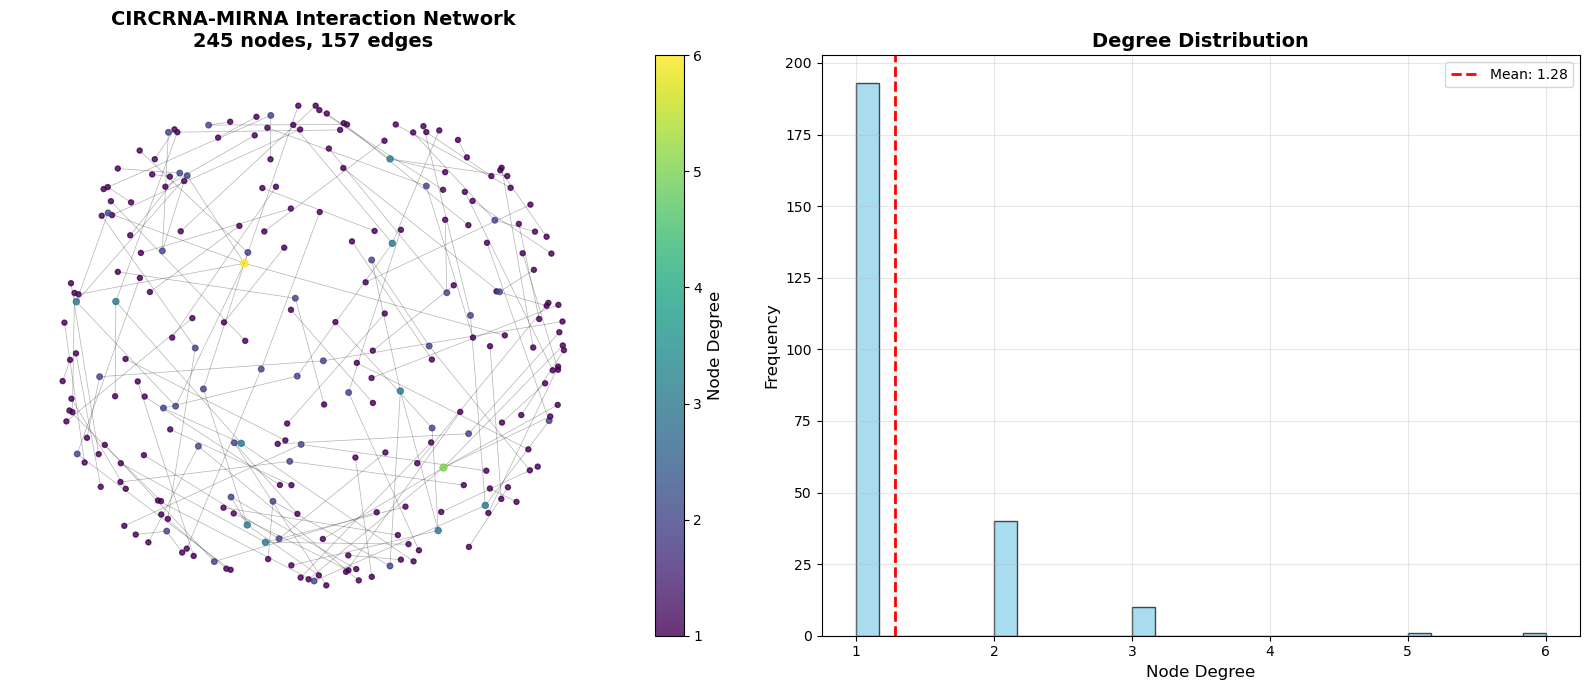


Top 10 hub nodes (highest degree):
  1. Degree 6: UCACAGUGAACCGGUCUCUUU
  2. Degree 5: UGCUGCUGGCCAGAGCUCUUUUCACAUUGU...
  3. Degree 3: UGGCAGUGUAUUGUUAGCUGGU
  4. Degree 3: GUCAGAAUAAUGUCAAAGUGCUUACAGUGC...
  5. Degree 3: CAACCUGGAGGACUCCAUGCUG
  6. Degree 3: GUCUUCGUCCCAGCAUGUUGGAGUCGUCCU...
  7. Degree 3: GGUUUCCGAAGGUCCGGUGAUAUCUAUGAU...
  8. Degree 3: UGGAAUGUAAAGAAGUAUGUAU
  9. Degree 3: UCAAAUGCUCAGACUCCUGUGGU
  10. Degree 3: UCCAGGAAAGAGUGUCUGUGGCAGUUAAUA...


In [19]:
def build_graph(df):
    if not hasattr(sp, "coo_array"):
        sp.coo_array = sp.coo_matrix

    # Build graph
    G = nx.from_pandas_edgelist(df, source="RNA_sequence_x", target="RNA_sequence_y")

    # Compute node degrees
    degrees = dict(G.degree())
    degree_values = list(degrees.values())

    # Compute and print statistics
    avg_degree = np.mean(degree_values)
    std_degree = np.std(degree_values)
    max_degree = np.max(degree_values)
    min_degree = np.min(degree_values)

    print(f"Graph Statistics:")
    print(f"  Nodes: {G.number_of_nodes()}")
    print(f"  Edges: {G.number_of_edges()}")
    print(f"  Average degree: {avg_degree:.2f}")
    print(f"  Std deviation: {std_degree:.2f}")
    print(f"  Min degree: {min_degree}")
    print(f"  Max degree: {max_degree}")

    # Compute network metrics
    density = nx.density(G)
    print(f"  Network density: {density:.4f}")

    # Find connected components
    num_components = nx.number_connected_components(G)
    largest_cc = max(nx.connected_components(G), key=len)
    print(f"  Connected components: {num_components}")
    print(f"  Largest component size: {len(largest_cc)}")

    # Create visualization with improved layout
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Left plot: Main network visualization with degree-based coloring
    ax1 = axes[0]
    pos = nx.spring_layout(G, k=0.5, seed=42, iterations=50)

    # Color nodes by degree
    node_colors = [degrees[node] for node in G.nodes()]
    nodes = nx.draw_networkx_nodes(
        G, pos, 
        node_size=[v * 3 + 10 for v in degree_values],  # Size proportional to degree
        node_color=node_colors,
        cmap=plt.cm.viridis,
        alpha=0.8,
        ax=ax1
    )

    nx.draw_networkx_edges(G, pos, width=0.5, alpha=0.3, ax=ax1)

    # Add colorbar
    cbar = plt.colorbar(nodes, ax=ax1)
    cbar.set_label('Node Degree', fontsize=12)

    ax1.set_title(f'{interaction.replace("_", "-").upper()} Interaction Network\n'
                f'{G.number_of_nodes()} nodes, {G.number_of_edges()} edges',
                fontsize=14, fontweight='bold')
    ax1.axis('off')

    # Right plot: Degree distribution
    ax2 = axes[1]
    ax2.hist(degree_values, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    ax2.axvline(avg_degree, color='red', linestyle='--', linewidth=2, label=f'Mean: {avg_degree:.2f}')
    ax2.set_xlabel('Node Degree', fontsize=12)
    ax2.set_ylabel('Frequency', fontsize=12)
    ax2.set_title('Degree Distribution', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(interaction + "_graph_enhanced.pdf", dpi=300, bbox_inches='tight')
    plt.show()

    # Additional visualization: Top hub nodes
    top_k = min(10, len(degrees))
    top_hubs = sorted(degrees.items(), key=lambda x: x[1], reverse=True)[:top_k]

    print(f"\nTop {top_k} hub nodes (highest degree):")
    for i, (node, deg) in enumerate(top_hubs, 1):
        node_display = node[:30] + "..." if len(node) > 30 else node
        print(f"  {i}. Degree {deg}: {node_display}")

build_graph(filtered_df)

## Data Augmentation
The data augmentation enforces invariance to molecule order and data orientation, in particular number of data is increased by four times:
1.   Original row
2.   Row with the two RNA sequences flipped
3.   Row with the two RNA sequences swapped
4.   Row with the two RNA sequences flipped and swapped



In [20]:
# Data Augmentation.

# Function to flip a sequence
def flip_sequence(seq):
    return seq[::-1]

# Function to augment a row
def augment_row(row):
    augmented_rows = []

    # 1. Original row (as-is)
    augmented_rows.append(row.copy())

    # 2. Row with both RNA_sequence_x and RNA_sequence_y flipped
    flipped_both_row = row.copy()
    flipped_both_row['RNA_sequence_x'] = flip_sequence(row['RNA_sequence_x'])
    flipped_both_row['RNA_sequence_y'] = flip_sequence(row['RNA_sequence_y'])
    augmented_rows.append(flipped_both_row)

    # 3. Row with RNA_sequence_x and RNA_sequence_y swapped (and Category_x, Category_y)
    swapped_row = row.copy()
    swapped_row['RNA_sequence_x'], swapped_row['RNA_sequence_y'] = row['RNA_sequence_y'], row['RNA_sequence_x']
    swapped_row['Category_x'], swapped_row['Category_y'] = row['Category_y'], row['Category_x']
    augmented_rows.append(swapped_row)

    # 4. Swapped and flipped both RNA_sequence_x and RNA_sequence_y
    swapped_flipped_both_row = swapped_row.copy()
    swapped_flipped_both_row['RNA_sequence_x'] = flip_sequence(swapped_row['RNA_sequence_x'])
    swapped_flipped_both_row['RNA_sequence_y'] = flip_sequence(swapped_row['RNA_sequence_y'])
    augmented_rows.append(swapped_flipped_both_row)

    return augmented_rows

# Function to perform data augmentation on the entire dataframe
def augment_dataframe(df):
    augmented_data = []
    for _, row in df.iterrows():
        augmented_data.extend(augment_row(row))
    return pd.DataFrame(augmented_data)

# Apply data augmentation on both the training and testing sets
augmented_train_df = augment_dataframe(train_df)
augmented_test_df = augment_dataframe(test_df)
train_df_noaug = train_df
test_df_noaug = test_df
# Print the number of rows in the augmented sets
print(f"Augmented training set size: {len(augmented_train_df)}")
print(f"Augmented testing set size: {len(augmented_test_df)}")
print(f"not Augmented train set size: {len(train_df_noaug)}")
print(f"not Augmented test set size: {len(test_df_noaug)}")

train_df = augmented_train_df
test_df = augmented_test_df

# Shuffle the training DataFrame
train_df_shuffled = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Shuffle the test DataFrame
test_df_shuffled = test_df.sample(frac=1, random_state=42).reset_index(drop=True)

train_df_noauf = train_df_noaug.sample(frac=1, random_state=42).reset_index(drop=True)

test_df_noauf = test_df_noaug.sample(frac=1, random_state=42).reset_index(drop=True)

Augmented training set size: 508
Augmented testing set size: 128
not Augmented train set size: 127
not Augmented test set size: 32


## Negative samples generation

Negative pairs are generated by replacing one molecule in each positive pair with another of the same type not known to interact. For every positive instance, 20 negatives are sampled (n = 20) to approximate the imbalance typical of ncRNA interaction data.

In [21]:
# Step 3: Negatives generation.
def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def flip_sequence(seq):
    return seq[::-1]


# ----------------------------
# negative sampling
# ----------------------------
def worker_task_type_aware(positives_chunk, true_pairs_set, candidates, neg_ratio):
    sampled_pairs = []
    for seq_x in positives_chunk:
        for _ in range(neg_ratio):
            success = False
            for _retry in range(100):  # max 100 retries
                seq_y = random.choice(candidates) # SAMPLE ONE UNIQUE SEQ. from candidates
                pair_frozen = frozenset((seq_x, seq_y))
                # ensure uniqueness and exclusion of positives
                if (pair_frozen not in true_pairs_set and
                        pair_frozen not in map(frozenset, sampled_pairs)):
                    sampled_pairs.append((seq_x, seq_y))
                    success = True
                    break
            if not success:
                continue  # skip if no valid negative found
    return sampled_pairs

def sample_negatives(pos_pairs, elements,
                     neg_ratio=20, num_workers=10):

    # true positive pairs + flipped/special cases
    true_pairs_set = set(frozenset(p) for p in pos_pairs)
    special_cases = set()
    for a, b in pos_pairs:
        a_f, b_f = flip_sequence(a), flip_sequence(b)
        special_cases.update({
            frozenset((a, a)), frozenset((b, b)),
            frozenset((a_f, a_f)), frozenset((b_f, b_f)),
            frozenset((a, b_f)), frozenset((b, a_f)),
            frozenset((a, a_f)), frozenset((b, b_f))
        })
    true_pairs_set.update(special_cases)
    # split positives across workers
    positives = [a for a, _ in pos_pairs]
    chunk_size = max(1, len(positives) // num_workers)
    chunks = [positives[i:i + chunk_size] for i in range(0, len(positives), chunk_size)]
    sampled_negatives = []
    with Pool(processes=num_workers) as pool:
        async_results = [
            pool.apply_async(worker_task_type_aware,
                             args=(chunk, true_pairs_set, elements, neg_ratio))
            for chunk in chunks
        ]
        for ar in tqdm(async_results, desc="Sampling negatives"):
            sampled_negatives.extend(ar.get())
    # remove duplicates
    sampled_negatives = list(dict.fromkeys(sampled_negatives))

    # Remove duplicates while treating (A, B) as different from (B, A)
    sampled_negatives = list(set(sampled_negatives))

    return sampled_negatives


# ----------------------------
# Cross-validation preparation (main) - but single fold
# ----------------------------
def prepare_cv_data(folds,
                    random_state=42,
                    neg_ratio=21,
                    num_workers=10):
    """
    Returns folds: list of dicts. Each dict:
      { "train": {"positives": [( (s1,s2),(t1,t2) ), ...], "negatives": [...]},
        "test":  {...} }
    """

    # ----------------------------
    # Convert DataFrame to tuple format
    # ----------------------------
    def attach_pairs_with_types(instances):
        out = []
        if isinstance(instances, pd.DataFrame):
            iter_rows = instances.iterrows()
            for _, row in iter_rows:
                seq1 = row["RNA_sequence_x"]
                seq2 = row["RNA_sequence_y"]
                t1 = 'RNA'
                t2 = 'RNA'
                out.append([(seq1, seq2), (t1, t2)])
        elif isinstance(instances, list):
            for row in instances:
                if isinstance(row, dict):  # dict case
                    seq1 = row.get("RNA_sequence_x")
                    seq2 = row.get("RNA_sequence_y")
                    t1 = 'RNA'
                    t2 = 'RNA'
                elif isinstance(row, tuple):  # tuple (seq1, seq2)
                    seq1, seq2 = row
                    t1 = 'RNA'
                    t2 = 'RNA'
                else:
                    raise TypeError(f"Unsupported row type: {type(row)}")
                out.append([(seq1, seq2), (t1, t2)])
        else:
            raise TypeError(f"Unsupported instances type: {type(instances)}")
        return out

    # ----------------------------
    # K-fold negative sampling
    # ----------------------------

    folds_data = []

    for fold in folds:

        train_pos_aug = fold["train"]
        test_pos_aug = fold["test"]

        # ----------------------------
        # Split-specific candidate sequences
        # ----------------------------
        train_candidates = pd.unique(train_pos_aug[['RNA_sequence_x','RNA_sequence_y']].values.ravel())
        test_candidates = pd.unique(test_pos_aug[['RNA_sequence_x','RNA_sequence_y']].values.ravel())

        train_pairs = list(zip(train_pos_aug["RNA_sequence_x"], train_pos_aug["RNA_sequence_y"]))
        test_pairs  = list(zip(test_pos_aug["RNA_sequence_x"], test_pos_aug["RNA_sequence_y"]))

        # Negatives sampling
        train_negs = sample_negatives(train_pairs, train_candidates,
                                      neg_ratio=neg_ratio)
        test_negs = sample_negatives(test_pairs, test_candidates,
                                     neg_ratio=neg_ratio)


        folds_data.append({
            "train": {
                "positives": attach_pairs_with_types(train_pos_aug),
                "negatives": attach_pairs_with_types(train_negs),
            },
            "test": {
                "positives": attach_pairs_with_types(test_pos_aug),
                "negatives": attach_pairs_with_types(test_negs),
            },
        })

    return folds_data


In [22]:
folds = [{"train": train_df, "test": test_df}]

neg_ratio = 20 # negatives per positive,

folds = prepare_cv_data(folds, random_state=42, neg_ratio=neg_ratio)

print(f"Prepared {len(folds)} folds. Example fold sizes:")
for i, f in enumerate(folds):
    print(f" Fold {i}: train_pos={len(f['train']['positives'])}, train_neg={len(f['train']['negatives'])}, "
          f"test_pos={len(f['test']['positives'])}, test_neg={len(f['test']['negatives'])}")

# optional: save per-fold pickles for quicker per-fold loading/inspection
out_dir = f"./FFNN_training/folds_" + interaction
os.makedirs(out_dir, exist_ok=True)
for i, f in enumerate(folds):
    per_path = os.path.join(out_dir, f"fold_{i}.pkl")
    with open(per_path, "wb") as fh:
        pickle.dump(f, fh, protocol=pickle.HIGHEST_PROTOCOL)
print(f"Saved individual fold pickles -> {out_dir}/")

Sampling negatives: 100%|██████████| 11/11 [00:00<00:00, 508.03it/s]

Prepared 1 folds. Example fold sizes:
 Fold 0: train_pos=508, train_neg=10018, test_pos=128, test_neg=2544
Saved individual fold pickles -> ./FFNN_training/folds_circrna_mirna/


## Export to FASTA file
Exporting to a FASTA file the list of all unique sequences and their flipped version

In [23]:
# Generate a list of unique sequences and their flipped versions
filtered_sequences = pd.concat([
    filtered_df['RNA_sequence_x'], 
    filtered_df['RNA_sequence_y']]).unique() # only export to fasta the filtered sequences
filtered_sequences_and_flipped = list(filtered_sequences) + [flip_sequence(seq) for seq in filtered_sequences]
filtered_sequences_and_flipped = list(set(filtered_sequences_and_flipped))

# Function to save sequences to a FASTA file
def save_to_fasta(sequences, filename):
    with open(filename, "w") as f:
        for i, seq in enumerate(sequences):
            f.write(f">sequence_{i+1}\n{seq}\n")

# Save the unique sequences and their flipped versions to a FASTA file
fasta_filename = interaction + "_unique_sequences_with_flipped.fasta"
save_to_fasta(filtered_sequences_and_flipped, fasta_filename)

print(f"Saved {len(filtered_sequences_and_flipped)} unique sequences (including flipped) to {fasta_filename}")

Saved 490 unique sequences (including flipped) to circrna_mirna_unique_sequences_with_flipped.fasta


# Part 2 - FFNN data preparation

## Embedings extraction using RNA-FM pre-trained model
```
!pip install torch
!pip install numpy
```
Folder to run the script: `RNA-FM/redevelop/`

```
conda activate RNA-FM &&
cd /home/utente/bioinformatics_project/RNA-FM/redevelop &&
python launch/predict.py \
  --config="pretrained/extract_embedding.yml" \
  --data_path="./data/circrna_mirna/circrna_mirna_unique_sequences_with_flipped.fasta" \
  --save_dir="./results/circrna_mirna" \
  --save_frequency 1 \
  --save_embeddings
```     

In [24]:
print(
    'conda activate RNA-FM &&\n'
    'cd /home/utente/bioinformatics_project/RNA-FM/redevelop &&\n'
    'python launch/predict.py \\\n'
    '--config="pretrained/extract_embedding.yml" \\\n '
    f'--data_path="./data/{interaction}/{interaction}_unique_sequences_with_flipped.fasta" \\\n'
    f'--save_dir="./results/{interaction}" \\\n'
    '--save_frequency 1 \\\n'
    '--save_embeddings'
    )

conda activate RNA-FM &&
cd /home/utente/bioinformatics_project/RNA-FM/redevelop &&
python launch/predict.py \
--config="pretrained/extract_embedding.yml" \
 --data_path="./data/circrna_mirna/circrna_mirna_unique_sequences_with_flipped.fasta" \
--save_dir="./results/circrna_mirna" \
--save_frequency 1 \
--save_embeddings


## Pooling of the embedding matrices

In [25]:
# Load the pickle file
def load_pkl(file_path):
  with open(file_path, "rb") as f:
      data = pickle.load(f)
  return data


def read_fasta(fasta_path):
  """
  Read sequences and IDs from a FASTA file.

  Parameters:
      fasta_path (str): Path to the FASTA file.

  Returns:
      list of tuples: [(id, sequence), ...]
  """
  entries = []
  seq = []
  seq_id = None
  with open(fasta_path, "r") as f:
      for line in f:
          line = line.strip()
          if not line:
              continue
          if line.startswith(">"):
              if seq_id and seq:
                  entries.append((seq_id, "".join(seq)))
                  seq = []
              seq_id = line[1:].strip()  # remove ">"
          else:
              seq.append(line)
      if seq_id and seq:
          entries.append((seq_id, "".join(seq)))
  return entries


def get_sequence_embeddings(fasta_file, embeddings_paths):
  """
  Given a FASTA file of unique sequences,
  create a dictionary mapping each sequence to its embedding.

  The combined embedding is computed by:
    - Max pooling along the sequence length dimension (dim=0)
    - Average pooling along the sequence length dimension (dim=0)
    - Concatenating the two pooled results along the feature dimension (dim=-1)

  The embedding file for each sequence is expected to be named '{id}.npy'
  in the directory embeddings_paths.

  Parameters:
      fasta_file (str): Path to the FASTA file containing unique sequences.
      embeddings_paths (str): Path to the directory containing embedding files.

  Returns:
      dict: Dictionary where keys are sequences and values are the combined embeddings (torch.Tensor).

  Raises:
      ValueError: If duplicate sequences are found in the FASTA.
  """

  fasta_entries = read_fasta(fasta_file)
  #print(fasta_entries)
  sequence_embeddings = {}

  for seq_id, seq in fasta_entries:
      if seq in sequence_embeddings:
          raise ValueError(f"Duplicate sequence found in FASTA: {seq[:30]}...")
      #print(seq_id)

      # Build filename from ID
      embedding_file = os.path.join(embeddings_path, f"{seq_id}.npy")
      if not os.path.exists(embedding_file):
          print(f"Warning: Embedding file not found for {seq_id}")
          continue

      embedding_np = np.load(embedding_file)
      embedding = torch.from_numpy(embedding_np)
      #print(len(embedding))

      # Pooling along sequence length
      max_pooled, _ = embedding.max(dim=0)
      avg_pooled = embedding.mean(dim=0)
      #print(len(max_pooled))
      #print(len(avg_pooled))

      combined_embedding = torch.cat([max_pooled, avg_pooled], dim=-1)
      #print(len(combined_embedding))
      #print(combined_embedding)

      # Store embedding (key = sequence, value = embedding)
      sequence_embeddings[seq] = combined_embedding
      #break

  return sequence_embeddings

file_path_unique = f'../RNA-FM/redevelop/data/{interaction}/{interaction}_unique_sequences_with_flipped.fasta'
#embeddings_path = f'../RNA-FM/redevelop/results/{interaction}/representations/'
embeddings_path = f'/home/utente/bioinformatics_project/RNA-FM/redevelop/results/{interaction}/representations/'
sequence_embeddings_dict = get_sequence_embeddings(file_path_unique, embeddings_path)

out_path = f'./FFNN_training/{interaction}_dictionary_pooled_embeddings_RNAFM.p'
with open(out_path, 'wb') as f:
    pickle.dump(sequence_embeddings_dict, f)


# Part 3 - FFNN Training

circrna_mirna
Available hyperparameter presets: Baseline, Capacity_Boost, Reg_Dropout, Reduce_Capacity, Bal_Neg_Focus
Using hyperparameter preset: Baseline
Loaded embeddings dict with 490 entries
Device: cuda
Loaded 1 per-fold pickles from ./FFNN_training/folds_circrna_mirna

=== Fold 0 ===
 Train samples after reduction: 10526 (pos=508, neg=10018)
Fold 0 Epoch 1/50 TrainLoss=0.598037 ValLoss=0.340352 LR=2.50e-04
Fold 0 Epoch 2/50 TrainLoss=0.491171 ValLoss=0.358830 LR=3.75e-04
Fold 0 Epoch 3/50 TrainLoss=0.408965 ValLoss=0.581139 LR=5.00e-04
Fold 0 Epoch 4/50 TrainLoss=0.377763 ValLoss=0.502704 LR=5.00e-04
Fold 0 Epoch 5/50 TrainLoss=0.335192 ValLoss=0.475857 LR=4.99e-04
Fold 0 Epoch 6/50 TrainLoss=0.263881 ValLoss=0.636014 LR=4.98e-04
Fold 0 Epoch 7/50 TrainLoss=0.238117 ValLoss=0.686756 LR=4.95e-04
Fold 0 Epoch 8/50 TrainLoss=0.187515 ValLoss=0.588221 LR=4.91e-04
Fold 0 Epoch 9/50 TrainLoss=0.170521 ValLoss=0.838014 LR=4.86e-04
Fold 0 Epoch 10/50 TrainLoss=0.139096 ValLoss=0.665321 

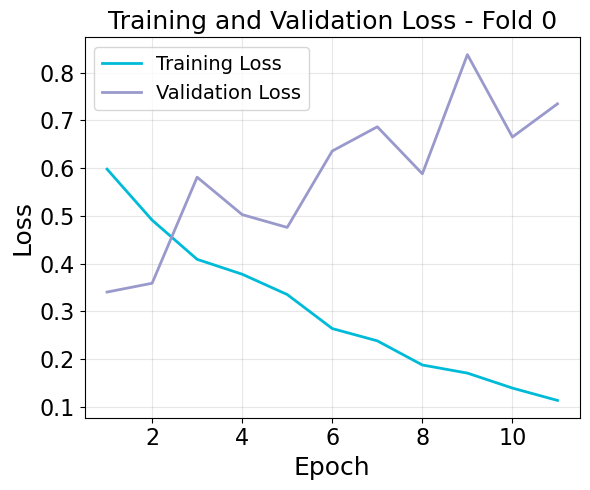

 Fold 0  optimal threshold (val MCC): 0.01
 Fold 0 metrics: {'fold': 0, 'n_train': 8420, 'n_val': 2106, 'n_test': 2672, 'threshold': 0.01, 'accuracy': 0.7788173652694611, 'balanced_accuracy': 0.690939465408805, 'precision': 0.12357723577235773, 'recall': 0.59375, 'f1': 0.20457604306864066, 'auroc': 0.7927200029481131, 'auprc': 0.22204877430136571}

Per-fold results:


/home/utente/miniconda3/envs/RNA-FM/lib/python3.8/site-packages/sklearn/metrics/_classification.py:870: RuntimeWarning: invalid value encountered in double_scalars
  mcc = cov_ytyp / np.sqrt(cov_ytyt * cov_ypyp)


,fold,n_train,n_val,n_test,threshold,accuracy,balanced_accuracy,precision,recall,f1,auroc,auprc
0,0,8420,2106,2672,0.01,0.778817,0.690939,0.123577,0.59375,0.204576,0.79272,0.222049



Aggregated metrics (mean ± std):


,mean,std
accuracy,0.7788,NaN
balanced_accuracy,0.6909,NaN
precision,0.1236,NaN
recall,0.5938,NaN
f1,0.2046,NaN
auroc,0.7927,NaN
auprc,0.2220,NaN


Saved metrics to ./FFNN_training/cv_training_results_full_circrna_mirna.pkl


In [26]:
print(interaction)
# Paths of files coming from notebooks 1 and 2
dict_path = f'./FFNN_training/{interaction}_dictionary_pooled_embeddings_RNAFM.p'   # embeddings pickle file
folds_dir = f"./FFNN_training/folds_{interaction}" # dataset file, divided in train/test

import os
import pickle
import math
import random
import gc
from math import ceil
from tqdm import tqdm
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve)
from sklearn.metrics import f1_score
from sklearn.metrics import matthews_corrcoef
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Cross-fold training script.
# MAX AND AVG POOLING
# ----------------------------
# Hyperparameters
# ----------------------------
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)


if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# use_l2_regularization = False  # controls whether weight decay is applied
# l2_lambda = 5e-4  # L2 coefficient when enabled
# print(f"L2 regularization {'enabled' if use_l2_regularization else 'disabled'} (lambda={l2_lambda if use_l2_regularization else 0.0})")

hyperparameter_configs = {
    "Baseline": {
        "input_dimension": 2560,
        "hidden_dimension": 1024,
        "num_layers": 4,
        "dropout": 0.2,
        "batch_size": 512,
        "learning_rate": 5e-4,
        "min_lr": 5e-5,
        "epochs": 50,
        "warmup_epochs": 4,
        "patience": 10,
        "train_negative_reduction_factor": 1,
        "validation_split_ratio": 0.20
    },
    "Capacity_Boost": {
        "input_dimension": 2560,
        "hidden_dimension": 1536,         # CHANGED: Increased width
        "num_layers": 5,                  # CHANGED: Increased depth
        "dropout": 0.25,                  # CHANGED: Slightly higher dropout
        "batch_size": 512,
        "learning_rate": 3e-4,            # CHANGED: Lower LR for larger model
        "min_lr": 3e-5,                   # CHANGED: Lower min LR
        "epochs": 70,                     # CHANGED: Longer training
        "warmup_epochs": 6,               # CHANGED: Longer warmup
        "patience": 14,                   # CHANGED: Increased patience
        "train_negative_reduction_factor": 1,
        "validation_split_ratio": 0.20
    },
    "Reg_Dropout": {
        "input_dimension": 2560,
        "hidden_dimension": 1280,         # CHANGED: Increased width
        "num_layers": 4,
        "dropout": 0.35,                  # CHANGED: High dropout for regularization
        "batch_size": 384,                # CHANGED: Smaller batch size
        "learning_rate": 4e-4,            # CHANGED: Adjusted LR
        "min_lr": 4e-5,                   # CHANGED: Adjusted min LR
        "epochs": 60,                     # CHANGED: Longer training
        "warmup_epochs": 5,               # CHANGED: Longer warmup
        "patience": 12,                   # CHANGED: Increased patience
        "train_negative_reduction_factor": 2, # CHANGED: More negative samples
        "validation_split_ratio": 0.18    # CHANGED: Slightly smaller validation set
    },
    "Reduce_Capacity": {
        "input_dimension": 2560,
        "batch_size": 512,
        "train_negative_reduction_factor": 1,
        "validation_split_ratio": 0.2,
        "epochs": 50,
        "learning_rate": 1e-4,    # CHANGED: 5e-4 -> 1e-4
        "num_layers": 2,          # CHANGED: Reduced depth
        "dropout": 0.5,           # CHANGED: High dropout for strong regularization
        "hidden_dimension": 256,  # CHANGED: Reduced width
        "warmup_epochs": 4,
        "patience": 10,
        "min_lr": 5e-5,
    },
    "Bal_Neg_Focus": {
        "input_dimension": 2560,
        "hidden_dimension": 1152,         # CHANGED: Slightly increased width
        "num_layers": 4,
        "dropout": 0.3,                   # CHANGED: Higher dropout
        "batch_size": 512,
        "learning_rate": 5e-4,
        "min_lr": 4e-5,                   # CHANGED: Adjusted min LR
        "epochs": 65,                     # CHANGED: Longer training
        "warmup_epochs": 5,               # CHANGED: Longer warmup
        "patience": 10,
        "train_negative_reduction_factor": 3, # CHANGED: Heavily weighted negatives
        "validation_split_ratio": 0.25    # CHANGED: Larger validation set
    }
}

print("Available hyperparameter presets:", ', '.join(hyperparameter_configs.keys()))
selected_config_name = "Baseline"  # change to try other presets
if selected_config_name not in hyperparameter_configs:
    raise ValueError(f"Unknown hyperparameter preset: {selected_config_name}")
selected_config = hyperparameter_configs[selected_config_name]
for _param, _value in selected_config.items():
    globals()[_param] = _value
print(f"Using hyperparameter preset: {selected_config_name}")
pdf_name_prefix = f"{selected_config_name}_"


out_models_dir = f"./FFNN_training/models_by_fold_{interaction}"
os.makedirs(out_models_dir, exist_ok=True)
save_metrics_path = f"./FFNN_training/cv_training_results_full_{interaction}.pkl"
save_plots_dir = f"./FFNN_training/cv_plots/{interaction}/concat_pool"
os.makedirs(save_plots_dir, exist_ok=True)


# embeddings
if not os.path.exists(dict_path):
    raise FileNotFoundError(f"Embeddings dict not found at {dict_path}")
with open(dict_path, 'rb') as fh:
    embeddings_dict = pickle.load(fh)
print("Loaded embeddings dict with", len(embeddings_dict), "entries")


# Colors / fonts 
color2 = '#9999CC'
color3 = '#00BBD8'
color_green = '#88B04B'
color_red = '#FF765B'
font_ticks = 16
font_labels = 18
heat0 = color_green
heat2 = '#204900'
heat3 = '#102A00'
cv_folds_path = ''

custom_cmap = LinearSegmentedColormap.from_list("soft_oranges", [heat0, heat2, heat3])

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

# ----------------------------
# Load folds and embeddings
# ----------------------------
if os.path.isdir(folds_dir):
    files = sorted([p for p in os.listdir(folds_dir) if p.endswith('.pkl')])
    folds = []
    for fn in files:
        with open(os.path.join(folds_dir, fn), 'rb') as fh:
            folds.append(pickle.load(fh))
    print(f"Loaded {len(folds)} per-fold pickles from {folds_dir}")
else:
    raise FileNotFoundError(f"Neither {cv_folds_path} nor directory {folds_dir} found.")


# Convert pair lists into numpy arrays (embeddings) and labels
def pairs_to_arrays(pairs_list, embeddings_dict, label):
    X_list = []
    y_list = []
    missing = 0
    for (s1, s2), (t1, t2) in pairs_list:
        if s1 not in embeddings_dict or s2 not in embeddings_dict:
            missing += 1
            continue
        e1 = np.asarray(embeddings_dict[s1], dtype=np.float32)
        e2 = np.asarray(embeddings_dict[s2], dtype=np.float32)
        # keep last 640 of each like original notebook
        e1s = e1
        e2s = e2
        if e1s.shape[0] < 1280 or e2s.shape[0] < 1280:
            # if shorter than 640, pad with zeros to 640 to keep shape consistent
            e1s = np.pad(e1s, (1280 - e1s.shape[0], 0), mode='constant') if e1s.shape[0] < 1280 else e1s
            e2s = np.pad(e2s, (1280 - e2s.shape[0], 0), mode='constant') if e2s.shape[0] < 1280 else e2s
        X_list.append(np.concatenate([e1s, e2s], axis=0))
        y_list.append(int(label))
    if missing:
        print(f"  Skipped {missing} pairs due to missing embeddings.")
    if len(X_list) == 0:
        return None, None
    X = np.stack(X_list)
    y = np.array(y_list, dtype=np.int64)
    return X, y




# Balanced batch sampler (same logic as notebook)
def get_data_loaders_without_replacement_from_arrays(X_train, y_train, X_valid, y_valid, batch_size, neg_batch_ratio=0.7, num_workers=2):
    """
    Build DataLoaders using BalancedBatchSampler logic but from numpy arrays.
    """
    train_tensor = torch.from_numpy(X_train).float()
    train_labels = torch.from_numpy(y_train)
    train_dataset = TensorDataset(train_tensor, train_labels)

    valid_tensor = torch.from_numpy(X_valid).float()
    valid_labels = torch.from_numpy(y_valid)
    valid_dataset = TensorDataset(valid_tensor, valid_labels)

    class BalancedBatchSampler:
        def __init__(self, labels, batch_size, neg_batch_ratio):
            self.labels = labels.numpy() if torch.is_tensor(labels) else labels
            self.batch_size = batch_size
            self.neg_batch_ratio = neg_batch_ratio
            self.neg_indices = np.where(self.labels == 0)[0]
            self.pos_indices = np.where(self.labels == 1)[0]
            self.num_neg_per_batch = int(batch_size * neg_batch_ratio)
            self.num_batches = len(self.neg_indices) // max(1, self.num_neg_per_batch)
            self.leftover_negatives = len(self.neg_indices) % max(1, self.num_neg_per_batch)

        def __iter__(self):
            neg_idx = np.random.permutation(self.neg_indices)
            pos_idx = self.pos_indices
            batch_start = 0
            for batch_num in range(self.num_batches):
                if batch_num < self.num_batches - 1 or self.leftover_negatives == 0:
                    num_neg_in_batch = self.num_neg_per_batch
                else:
                    num_neg_in_batch = self.leftover_negatives
                neg_batch = neg_idx[batch_start:batch_start + num_neg_in_batch]
                batch_start += num_neg_in_batch
                num_pos_in_batch = self.batch_size - num_neg_in_batch
                pos_batch = np.random.choice(pos_idx, num_pos_in_batch, replace=True)
                batch_indices = np.concatenate([neg_batch, pos_batch])
                np.random.shuffle(batch_indices)
                yield batch_indices.tolist()

        def __len__(self):
            return self.num_batches if self.num_batches > 0 else 1

    train_sampler = BalancedBatchSampler(train_labels, batch_size, neg_batch_ratio=0.7)
    train_loader = DataLoader(train_dataset, batch_sampler=train_sampler, num_workers=num_workers)
    valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    return train_loader, valid_loader

# InteractionNN 
class InteractionNN(nn.Module):
    def __init__(self, input_dim=input_dimension, hidden_dim=hidden_dimension, num_layers=num_layers, dropout=dropout):
        super(InteractionNN, self).__init__()
        layers = [nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(p=dropout)]
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(p=dropout))
        self.hidden_layers = nn.Sequential(*layers)
        self.output_layer = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.hidden_layers(x)
        x = self.output_layer(x)
        return torch.sigmoid(x).view(-1)

# learning rate scheduler with warmup
def cosine_annealing_with_warmup(epoch, warmup_epochs, max_epochs, min_lr=1e-5):
    if epoch < warmup_epochs:
        return (epoch + 1) / warmup_epochs
    else:
        cosine_decay = 0.5 * (1 + math.cos(math.pi * (epoch - warmup_epochs) / (max_epochs - warmup_epochs)))
        return (cosine_decay * (1 - min_lr) + min_lr)

# ----------------------------
# Cross-fold training
# ----------------------------

# collect confusion matrices across folds
cms = []
all_test_probs_all = []
all_test_labels_all = []
roc_curves = []
pr_curves = []
all_fold_metrics = []
weight_decay = l2_lambda if use_l2_regularization else 0.0

for fi, fold in enumerate(folds):
    print("\n=== Fold", fi, "===")
    train_pos = fold['train']['positives']
    train_neg = fold['train']['negatives']
    test_pos = fold['test']['positives']
    test_neg = fold['test']['negatives']

    # Build full training arrays from pairs
    Xp, yp = pairs_to_arrays(train_pos, embeddings_dict, label=1)
    Xn, yn = pairs_to_arrays(train_neg, embeddings_dict, label=0)

    if Xp is None and Xn is None:
        print("No training data for fold", fi); continue
    if Xp is None:
        X_all = Xn; y_all = yn
    elif Xn is None:
        X_all = Xp; y_all = yp
    else:
        X_all = np.concatenate([Xp, Xn], axis=0)
        y_all = np.concatenate([yp, yn], axis=0)

    # Optionally reduce negatives like original script
    # Separate positives and negatives to apply reduction factor conveniently
    pos_idx = np.where(y_all == 1)[0]
    neg_idx = np.where(y_all == 0)[0]
    # Shuffle negatives
    np.random.shuffle(neg_idx)
    reduced_neg_count = max(1, int(len(neg_idx) // train_negative_reduction_factor))
    neg_selected = neg_idx[:reduced_neg_count]
    selected_idx = np.concatenate([pos_idx, neg_selected])
    np.random.shuffle(selected_idx)
    X_sel = X_all[selected_idx]
    y_sel = y_all[selected_idx]

    print(f" Train samples after reduction: {len(y_sel)} (pos={sum(y_sel==1)}, neg={sum(y_sel==0)})")

    # split into train/val
    n_total = len(y_sel)
    n_train = int((1 - validation_split_ratio) * n_total)
    n_val = n_total - n_train
    indices = np.arange(n_total)
    np.random.shuffle(indices)
    train_inds = indices[:n_train]
    val_inds = indices[n_train:]

    X_train = X_sel[train_inds]; y_train = y_sel[train_inds]
    X_val = X_sel[val_inds]; y_val = y_sel[val_inds]

    # Standardize per fold using training data
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    # Prepare test set arrays
    Xp_test, yp_test = pairs_to_arrays(test_pos, embeddings_dict, label=1)
    Xn_test, yn_test = pairs_to_arrays(test_neg, embeddings_dict, label=0)
    if Xp_test is None and Xn_test is None:
        print("No test data for fold", fi); continue
    if Xp_test is None:
        X_test = Xn_test; y_test = yn_test
    elif Xn_test is None:
        X_test = Xp_test; y_test = yp_test
    else:
        X_test = np.concatenate([Xp_test, Xn_test], axis=0)
        y_test = np.concatenate([yp_test, yn_test], axis=0)
    X_test = scaler.transform(X_test)

    # Build DataLoaders using balanced sampler approach
    train_loader, val_loader = get_data_loaders_without_replacement_from_arrays(X_train, y_train, X_val, y_val, batch_size, neg_batch_ratio=0.5, num_workers=0)

    test_ds = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=0)

    # model, optimizer
    model = InteractionNN(input_dim=input_dimension, hidden_dim=hidden_dimension, num_layers=num_layers, dropout=dropout).to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda e: cosine_annealing_with_warmup(e, warmup_epochs, epochs, min_lr))
    criterion = nn.BCELoss()

    # training loop with early stopping on validation loss
    best_val_loss = float('inf')
    best_state = None
    epochs_no_improv = 0

    train_losses = []
    val_losses = []
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch in train_loader:
            xb, yb = batch
            xb = xb.to(device)
            yb = yb.to(device, dtype=torch.float32)
            optimizer.zero_grad()
            outputs = model(xb).view(-1)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / (len(train_loader) if len(train_loader)>0 else 1)
        train_losses.append(train_loss)

        # validation
        model.eval()
        total_val_loss = 0.0
        all_val_probs = []
        all_val_labels = []
        with torch.no_grad():
            for batch in val_loader:
                xb, yb = batch
                xb = xb.to(device)
                yb = yb.to(device, dtype=torch.float32)
                outputs = model(xb).view(-1)
                loss = criterion(outputs, yb)
                total_val_loss += loss.item()
                all_val_probs.extend(outputs.cpu().numpy())
                all_val_labels.extend(yb.cpu().numpy())
        val_loss = total_val_loss / (len(val_loader) if len(val_loader)>0 else 1)
        val_losses.append(val_loss)

        # scheduler step & early stop logic
        if val_loss < best_val_loss - 1e-8:
            best_val_loss = val_loss
            best_state = model.state_dict()
            epochs_no_improv = 0
            # save best per-fold
            per_model_path = os.path.join(out_models_dir, f"best_model_fold{fi}.pth")
            torch.save(best_state, per_model_path)
        else:
            epochs_no_improv += 1

        scheduler.step()
        lr_now = optimizer.param_groups[0]['lr']
        print(f"Fold {fi} Epoch {epoch+1}/{epochs} TrainLoss={train_loss:.6f} ValLoss={val_loss:.6f} LR={lr_now:.2e}")

        if epochs_no_improv >= patience:
            print(f"Early stopping on fold {fi} at epoch {epoch+1}")
            break

    # Plot training and validation loss
    plt.figure(figsize=(6, 5))
    plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss', color=color3, linewidth=2)
    plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color=color2, linewidth=2)
    plt.xlabel('Epoch', fontsize=font_labels)
    plt.ylabel('Loss', fontsize=font_labels)
    plt.title(f'Training and Validation Loss - Fold {fi}', fontsize=font_labels)
    plt.legend(fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.xticks(fontsize=font_ticks)
    plt.yticks(fontsize=font_ticks)
    plt.tight_layout()
    plt.savefig(os.path.join(save_plots_dir, f"{pdf_name_prefix}loss_curve_fold{fi}.pdf"), bbox_inches="tight")
    plt.show()
    plt.close()

    # restore best state
    if best_state is not None:
        model.load_state_dict(best_state)

    # Compute optimal threshold on validation 
    model.eval()
    val_probs = np.array(all_val_probs)
    val_labels = np.array(all_val_labels)
    thresholds = np.linspace(0, 1, 101)
    mcc_scores = []
    for thr in thresholds:
        preds_thr = (val_probs > thr).astype(np.int32)
        mcc_scores.append(matthews_corrcoef(val_labels, preds_thr))
    best_thr = thresholds[int(np.nanargmax(mcc_scores))]
    print(" Fold", fi, " optimal threshold (val MCC):", best_thr)

    # Evaluate on test set using best_thr
    all_test_probs = []
    all_test_labels = []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            outputs = model(xb).view(-1)
            all_test_probs.extend(outputs.cpu().numpy())
            all_test_labels.extend(yb.numpy())
    all_test_probs = np.array(all_test_probs)
    all_test_labels = np.array(all_test_labels)
    test_preds = (all_test_probs > best_thr).astype(int)

    # compute metrics on test
    acc = accuracy_score(all_test_labels, test_preds)
    bal_acc = balanced_accuracy_score(all_test_labels, test_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_test_labels, test_preds, average='binary', zero_division=0)
    try:
        auroc = roc_auc_score(all_test_labels, all_test_probs)
    except Exception:
        auroc = float('nan')
    try:
        auprc = average_precision_score(all_test_labels, all_test_probs)
    except Exception:
        auprc = float('nan')

    fold_metrics = {
        'fold': fi,
        'n_train': len(train_loader.dataset),
        'n_val': len(val_loader.dataset),
        'n_test': len(test_loader.dataset),
        'threshold': float(best_thr),
        'accuracy': float(acc),
        'balanced_accuracy': float(bal_acc),
        'precision': float(prec),
        'recall': float(rec),
        'f1': float(f1),
        'auroc': float(auroc),
        'auprc': float(auprc)
    }
    all_fold_metrics.append(fold_metrics)
    print(" Fold", fi, "metrics:", fold_metrics)

    # X boxplots and confusion matrices
    cm = confusion_matrix(all_test_labels, test_preds, normalize="true")
    cms.append(cm)
    all_test_probs_all.extend(all_test_probs)
    all_test_labels_all.extend(all_test_labels)

    try:
        fpr, tpr, _ = roc_curve(all_test_labels, all_test_probs)
        roc_curves.append((fi, fpr, tpr, auroc))
    except Exception:
        pass

    try:
        prec_vals, rec_vals, _ = precision_recall_curve(all_test_labels, all_test_probs)
        pr_curves.append((fi, rec_vals, prec_vals, auprc))
    except Exception:
        pass

    # clear memory
    del model, optimizer, scheduler, train_loader, val_loader, test_loader
    gc.collect()
    torch.cuda.empty_cache()

# ----------------------------
# Aggregate metrics across folds
# ----------------------------
df_res = pd.DataFrame(all_fold_metrics)
print("\nPer-fold results:")
display(df_res)

agg = df_res.drop(columns=['fold','n_train','n_val','n_test','threshold']).agg(['mean','std']).T
agg['mean'] = agg['mean'].round(4)
agg['std'] = agg['std'].round(4)
print("\nAggregated metrics (mean ± std):")
display(agg)

# =========================
# Plot metrics across folds
# =========================
colors = plt.cm.tab10.colors  # distinct colors
from matplotlib.backends.backend_pdf import PdfPages
metrics_to_plot = ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
# Custom display names
metric_display_names = {
    "accuracy": "ACCURACY",
    "balanced_accuracy": "BAL. ACC.",
    "precision": "PRECISION",
    "recall": "RECALL",
    "f1": "F1"
}

pdf_path = os.path.join(save_plots_dir, f"{pdf_name_prefix}metrics_summary_table.pdf")
with PdfPages(pdf_path) as pdf:
    plt.figure(figsize=(8, 4))
    ax = plt.gca()
    ax.axis('off')

    # Header row with display names
    header = ["Fold"] + [metric_display_names[m] for m in metrics_to_plot]
    table_data = [header]

    for _, row in df_res.iterrows():
        table_data.append(
            [int(row["fold"])] + [f"{row[m]:.3f}" for m in metrics_to_plot]
        )

    # Mean ± Std row
    mean_std_vals = [f"{df_res[m].mean():.3f} ± {df_res[m].std():.3f}" for m in metrics_to_plot]
    table_data.append(["Mean ± Std"] + mean_std_vals)

    # Draw table
    table = ax.table(cellText=table_data, loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)

    pdf.savefig()
    plt.close()

# =========================
# normalised confusion matrix averaged across folds
# =========================

cms = np.array(cms)
cm_mean = cms.mean(axis=0)
cm_std = cms.std(axis=0)

plt.figure(figsize=(6, 5))
ax = sns.heatmap(cm_mean, annot=True, fmt=".2%", cmap=custom_cmap,
                 xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
                 annot_kws={"size": font_ticks}, cbar_kws={"shrink": 0.9})

plt.xlabel('Predicted', fontsize=font_labels)
plt.ylabel('Actual', fontsize=font_labels)
plt.xticks(fontsize=font_ticks)
plt.yticks(fontsize=font_ticks)

cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(labelsize=font_ticks)

plt.savefig(os.path.join(save_plots_dir, f"{pdf_name_prefix}confusion_matrix_normalized_mean_std.pdf"), bbox_inches="tight")
plt.close()

# =========================
# boxplot 
# =========================

all_test_probs_all = np.array(all_test_probs_all)
all_test_labels_all = np.array(all_test_labels_all)

plt.figure(figsize=(8, 6))
box = plt.boxplot([all_test_probs_all[all_test_labels_all == 0],
                   all_test_probs_all[all_test_labels_all == 1]],
                  labels=["Negative", "Positive"], patch_artist=True)

# Set colors: red for negatives, green for positives
box['boxes'][0].set(facecolor=color_red)   # Negative
box['boxes'][1].set(facecolor=color_green) # Positive

# Median lines
for median in box['medians']:
    median.set(color='#FFD260', linewidth=2)

plt.ylabel("Predicted Probability", fontsize=font_labels)
plt.xticks(fontsize=font_ticks)
plt.yticks(fontsize=font_ticks)
plt.grid()

plt.savefig(os.path.join(save_plots_dir, f"{pdf_name_prefix}boxplot_probabilities_all_folds.pdf"), bbox_inches="tight")
plt.close()

# =========================
# Plot AUROC curves all folds
# =========================
plt.figure(figsize=(6, 5))
for fi, fpr, tpr, auroc in roc_curves:
    plt.plot(fpr, tpr, color=colors[fi % len(colors)],
             label=f"AUROC={auroc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate', fontsize=font_labels)
plt.ylabel('True Positive Rate', fontsize=font_labels)
plt.grid(True)
plt.legend(fontsize=12, loc="lower right")  # bigger legend inside, bottom-right
plt.tight_layout()
plt.savefig(os.path.join(save_plots_dir, f"{pdf_name_prefix}all_folds_roc_curves.pdf"), bbox_inches="tight")
plt.close()

# =========================
# Plot AUPRC curves all folds
# =========================
plt.figure(figsize=(6, 5))
for fi, rec_vals, prec_vals, auprc in pr_curves:
    plt.plot(rec_vals, prec_vals, color=colors[fi % len(colors)],
             label=f"AUPRC={auprc:.3f}")
plt.xlabel('Recall', fontsize=font_labels)
plt.ylabel('Precision', fontsize=font_labels)
plt.grid(True)
plt.legend(fontsize=12, loc="lower left")  # bigger legend inside, bottom-left
plt.tight_layout()
plt.savefig(os.path.join(save_plots_dir, f"{pdf_name_prefix}all_folds_pr_curves.pdf"), bbox_inches="tight")
plt.close()

# Save metrics and per-fold models metadata
with open(save_metrics_path, 'wb') as fh:
    pickle.dump({'per_fold': all_fold_metrics, 'aggregate': agg.to_dict()}, fh)
print("Saved metrics to", save_metrics_path)